# 01. От PDF к поисковому индексу

Первая часть из трёх. Берём статью *Attention Is All You Need* (arXiv 1706.03762, версия 7) и готовим её к поиску: извлекаем текст, таблицы и рисунки, режем документ на чанки и записываем их в Qdrant сразу в двух представлениях: dense-вектор и BM25.

```text
PDF → Docling (+ VLM для рисунков) → HybridChunker → чанки ┬→ dense-векторы ─┐
                                                          └→ BM25 ──────────┴→ Qdrant
```

Здесь нужны Qdrant, сервер embeddings и VLM. LLM для ответов понадобится только во [второй части](02_retrieval_and_answer.ipynb). Как всё запустить, описано в [SETUP.md](SETUP.md).

Почти все шаги кешируются в `outputs/indexes/<INDEX_NAME>/`. Первый запуск занимает пару минут: дольше всего идут OCR и описания рисунков. Повторный читает готовое с диска.

## 1. Настройки и подключение

`INDEX_NAME` — имя папки с результатами и коллекции в Qdrant. Если меняете документы, модель embeddings или размер чанка, задайте новое имя. Иначе ячейка ниже остановится: она сверяет настройки с теми, что записаны при первом запуске.

In [1]:
import sys
from pathlib import Path

# Ноутбук можно открыть из этой папки или из корня репозитория.
ROOT = Path.cwd() if (Path.cwd() / "helpers").is_dir() else Path.cwd() / "hybrid_rag_notebooks"
sys.path.insert(0, str(ROOT))

from helpers.settings import load_env  # noqa: E402

load_env(ROOT)

In [2]:
import json

import pandas as pd
from helpers.corpus import discover_documents, document_inventory, ensure_corpus
from helpers.settings import rag_settings, server_commands
from helpers.storage import check_config, write_json
from tqdm.auto import tqdm

CFG = rag_settings()
INDEX_NAME = "attention_v1"
COLLECTION = f"hybrid_rag_{INDEX_NAME}"
INDEX_DIR = ROOT / "outputs" / "indexes" / INDEX_NAME
DOCUMENTS_DIR = ROOT / "data" / "documents"

# Команды для отдельных терминалов; сама ячейка ничего не запускает.
for role, command in server_commands(CFG, roles=("embed", "vision")).items():
    print(f"# {role}\n{command}\n")

# embed
llama-server -hf mradermacher/Qwen3-Embedding-0.6B-GGUF:Q8_0 --alias mradermacher/Qwen3-Embedding-0.6B-GGUF:Q8_0 --embedding --pooling last --batch-size 8192 --ubatch-size 8192 --host 127.0.0.1 --port 8101 --ctx-size 8192 --parallel 1 --n-gpu-layers 999

# vision
llama-server -hf prithivMLmods/Xiaomi-OCR-0-GGUF:Q6_K --alias prithivMLmods/Xiaomi-OCR-0-GGUF:Q6_K --image-min-tokens 1024 --host 127.0.0.1 --port 8103 --ctx-size 8192 --parallel 1 --n-gpu-layers 999


PDF в Git не хранится. Если файла нет, скачаем его с arXiv. В любом случае сверим SHA256: эталонные ответы в `data/questions.jsonl` написаны именно по седьмой версии статьи.

Чтобы проиндексировать свои документы, положите их в `data/documents/` и пропустите эту ячейку.

In [3]:
pdf_path = ensure_corpus(ROOT)
print(pdf_path.relative_to(ROOT), f"{pdf_path.stat().st_size / 1e6:.1f} МБ")

data/documents/Attention is all you need.pdf 2.2 МБ


Подключаемся к моделям. Токенизатор берём у того же сервера embeddings (эндпоинт `/tokenize`). Тогда лимит в 512 токенов при нарезке совпадает с тем, как текст увидит модель embeddings.

BM25 считается локально через `fastembed`. В первый раз он скачивает с Hugging Face небольшой словарь со стоп-словами и стеммером.

In [4]:
from fastembed import SparseTextEmbedding
from helpers.clients import ModelAPI
from helpers.parsing import make_tokenizer
from qdrant_client import QdrantClient
from qdrant_client import models as qm

embedder = ModelAPI(CFG["embed_url"], CFG["embed_model"], "EMBED_API_KEY")
embedder.require_model()
vision = None
if CFG["vision"]:
    vision = ModelAPI(CFG["vision_url"], CFG["vision_model"], "VISION_API_KEY")
    vision.require_model()
qdrant = QdrantClient(url=CFG["qdrant_url"], timeout=120)
qdrant.get_collections()

dimension = len(embedder.embed(["probe"])[0])
tokenizer = make_tokenizer(embedder, CFG["max_tokens"])
bm25 = SparseTextEmbedding(CFG["sparse_model"])
print(f"embeddings: {CFG['embed_model']}, {dimension} измерений")
print(f"VLM: {CFG['vision_model'] if vision else 'выключена'}")

embeddings: mradermacher/Qwen3-Embedding-0.6B-GGUF:Q8_0, 1024 измерений
VLM: prithivMLmods/Xiaomi-OCR-0-GGUF:Q6_K


In [5]:
paths = discover_documents(DOCUMENTS_DIR)
INDEX_CONFIG = {
    "embed_model": CFG["embed_model"],
    "dimension": dimension,
    "doc_template": CFG["doc_template"],
    "query_template": CFG["query_template"],
    "sparse_model": CFG["sparse_model"],
    "max_tokens": CFG["max_tokens"],
    "ocr": CFG["ocr"],
    "vision_model": CFG["vision_model"] if CFG["vision"] else None,
    "vision_min_area": CFG["vision_min_area"],
    "collection": COLLECTION,
    "documents": document_inventory(paths, DOCUMENTS_DIR),
}
check_config(INDEX_DIR / "index.json", INDEX_CONFIG)
pd.DataFrame(INDEX_CONFIG["documents"])

,path,sha256
0,Attention is all you need.pdf,bdfaa68d8984f0dc02beaca527b76f207d99b666d31d1d...


## 2. Что Docling достаёт из PDF

Сначала восстанавливаем структуру документа: заголовки, абзацы, таблицы, рисунки, номера страниц. На чанки режем только потом. Если резать «сырой» текст окном фиксированной длины, легко оторвать строки таблицы от её шапки или подпись от рисунка.

Что делает Docling:
- раскладку страницы определяет своей моделью, таблицы восстанавливает через TableFormer;
- для текста внутри картинок и сканов запускает OCR (RapidOCR). Язык указываем явно: по умолчанию RapidOCR берёт китайскую модель, которая не читает кириллицу. RapidOCR использует только первый язык из списка, но кириллическая модель читает и латиницу;
- рисунки отдаёт нам с пикселями. Каждый крупный рисунок мы отправляем в VLM (Xiaomi-OCR) и вставляем полученное описание в документ сразу за ним, в тот же раздел и на ту же страницу.

Готовый `DoclingDocument` сохраняем в JSON. Повторный запуск не трогает ни Docling, ни VLM.

In [6]:
from docling.datamodel.accelerator_options import AcceleratorDevice, AcceleratorOptions
from docling.datamodel.base_models import ConversionStatus, InputFormat
from docling.datamodel.pipeline_options import OcrAutoOptions, PdfPipelineOptions
from docling.document_converter import DocumentConverter, ImageFormatOption, PdfFormatOption
from docling_core.types.doc import DoclingDocument
from helpers.parsing import add_image_descriptions

pdf_options = PdfPipelineOptions(
    do_ocr=CFG["ocr"],
    ocr_options=OcrAutoOptions(lang=["iso:ru", "iso:en"]),
    generate_picture_images=CFG["vision"],  # VLM нужны пиксели рисунков
    images_scale=2.0,
    accelerator_options=AcceleratorOptions(device=AcceleratorDevice(CFG["device"])),
)
converter = DocumentConverter(
    format_options={
        InputFormat.PDF: PdfFormatOption(pipeline_options=pdf_options),
        InputFormat.IMAGE: ImageFormatOption(pipeline_options=pdf_options),
    }
)

documents = []
for path, info in zip(paths, INDEX_CONFIG["documents"], strict=True):
    doc_id = info["sha256"][:16]
    cache = INDEX_DIR / "docling" / f"{doc_id}.json"
    if cache.exists():
        doc = DoclingDocument.model_validate_json(cache.read_text(encoding="utf-8"))
    else:
        print(f"Разбираем {info['path']}…", flush=True)
        result = converter.convert(path)
        if result.status != ConversionStatus.SUCCESS:
            raise RuntimeError(f"{info['path']}: {result.status.value} {result.errors}")
        doc = add_image_descriptions(result.document, path, vision, min_area=CFG["vision_min_area"])
        # Пишем на диск только документ, в котором уже есть все описания рисунков.
        write_json(cache, doc.model_dump(mode="json"))
    documents.append({"path": info["path"], "doc_id": doc_id, "doc": doc})

doc = documents[0]["doc"]
descriptions = [t for t in doc.texts if t.text.startswith("Image description:")]
print(
    f"Страниц: {len(doc.pages)}, таблиц: {len(doc.tables)}, рисунков: {len(doc.pictures)}, "
    f"описаний от VLM: {len(descriptions)}"
)

Страниц: 15, таблиц: 4, рисунков: 7, описаний от VLM: 5


Посмотрим на начало документа в Markdown. Именно этот текст дальше пойдёт в чанки. Формулы Docling по умолчанию не распознаёт и оставляет вместо них `<!-- formula-not-decoded -->`. Для этой статьи это заметная потеря: формула attention есть только в виде формулы.

In [7]:
print(doc.export_to_markdown()[:2500])

Provided proper attribution is provided, Google hereby grants permission to reproduce the tables and figures in this paper solely for use in journalistic or scholarly works.

## Attention Is All You Need

Ashish Vaswani∗ Google Brain avaswani@google.com Noam Shazeer∗ Google Brain noam@google.com Niki Parmar∗ Google Research nikip@google.com Jakob Uszkoreit∗ Google Research usz@google.com

Llion Jones∗ Google Research llion@google.com Aidan N. Gomez∗ † University of Toronto aidan@cs.toronto.edu Łukasz Kaiser∗ Google Brain lukaszkaiser@google.com Illia Polosukhin∗ ‡ illia.polosukhin@gmail.com

## Abstract

The dominant sequence transduction models are based on complex recurrent or convolutional neural networks that include an encoder and a decoder. The best performing models also connect the encoder and decoder through an attention mechanism. We propose a new simple network architecture, the Transformer, based solely on attention mechanisms, dispensing with recurrence and convolutions en

Таблицы Docling хранит структурированно, их можно сразу получить как DataFrame. Проверим таблицу 3 с ablation-экспериментами: на неё опирается несколько вопросов из набора.

In [8]:
for number, table in enumerate(doc.tables):
    caption = table.caption_text(doc)[:90]
    print(f"[{number}] стр. {table.prov[0].page_no}: {caption}")

TABLE = 2
doc.tables[TABLE].export_to_dataframe(doc=doc).head(12)

[0] стр. 6: Table 1: Maximum path lengths, per-layer complexity and minimum number of sequential opera
[1] стр. 8: Table 2: The Transformer achieves better BLEU scores than previous state-of-the-art models
[2] стр. 9: Table 3: Variations on the Transformer architecture. Unlisted values are identical to thos
[3] стр. 10: Table 4: The Transformer generalizes well to English constituency parsing (Results are on 


,,N,dmodel,dff,h,dk,dv,Pdrop,ϵls,train steps,PPL (dev),BLEU (dev),params ×106
0,base,6,512,2048,8,64,64,0.1,0.1,100K,4.92,25.8,65
1,,,,,1,512,512,,,,5.29,24.9,
2,,,,,4,128,128,,,,5.00,25.5,
3,(A),,,,16,32,32,,,,4.91,25.8,
4,,,,,32,16,16,,,,5.01,25.4,
5,,,,,,16,,,,,5.16,25.1,58
6,(B),,,,,32,,,,,5.01,25.4,60
7,,2,,,,,,,,,6.11,23.7,36
8,,4,,,,,,,,,5.19,25.3,50
9,,8,,,,,,,,,4.88,25.5,80


А вот что VLM написала про рисунки. Это обычный текст в документе, поэтому по нему работает и dense-поиск, и BM25.

In [9]:
for item in descriptions:
    page = item.prov[0].page_no if item.prov else "?"
    print(f"--- стр. {page}\n{item.text[:700]}\n")

--- стр. 3
Image description: This is a diagram of a two-step machine learning model, specifically a multi-head attention model with feedback loops, likely used in tasks like sequence classification or natural language processing. The diagram is divided into two main pathways: one for "Inputs" and one for "Outputs (shifted right)", each with their own processing chains.

**Left Pathway: Inputs**
- **Input Embedding**: This is the starting block, represented by a pink rectangle. It takes in "Inputs" (represented by a circular arrow and plus sign).
- **Positional Encoding**: This is another block, also a pink rectangle, which takes the input embedding and outputs a vector. This vector is then added to th

--- стр. 4
Image description: This is a diagram for Multi-Head Attention, which is a type of attention mechanism used in neural networks to process multi-head input data. The diagram consists of the following components, labels, numbers, and arrows:

1. **Input Points**: At the bottom o

### Сверка со страницей

Глазами проверить извлечение быстрее всего так: открыть страницу PDF и рядом текст, который из неё получился. На странице 5 раздел 3.2.2 про multi-head attention, там число голов и размерности. Для таблицы 3 поставьте `PAGE = 9`.

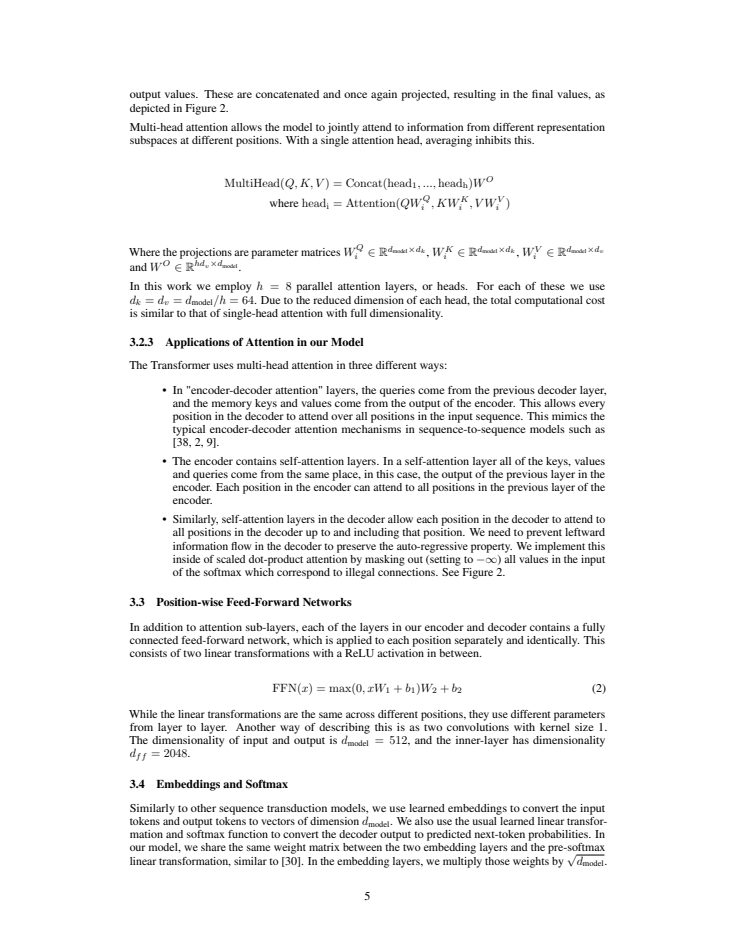

Multi-head attention allows the model to jointly attend to information from different representation subspaces at different positions. With a single attention head, averaging inhibits this.

<!-- formula-not-decoded -->

<!-- formula-not-decoded -->

Where the projections are parameter matrices W Q i ∈ Rdmodel×dk , W K i ∈ Rdmodel×dk , W V i ∈ Rdmodel×dv and W O ∈ Rhdv×dmodel .

In this work we employ h = 8 parallel attention layers, or heads. For each of these we use dk = dv = dmodel/h = 64. Due to the reduced dimension of each head, the total computational cost is similar to that of single-head attention with full dimensionality.

## 3.2.3 Applications of Attention in our Model

The Transformer uses multi-head attention in three different ways:

- In "encoder-decoder attention" layers, the queries come from the previous decoder layer, and the memory keys and values come from the output of the encoder. This allows every position in the decoder to attend over all positions in the input

In [10]:
import pypdfium2 as pdfium
from IPython.display import display

PAGE = 5  # нумерация с 1

with pdfium.PdfDocument(DOCUMENTS_DIR / documents[0]["path"]) as pdf:
    display(pdf[PAGE - 1].render(scale=1.2).to_pil())
print(doc.export_to_markdown(page_no=PAGE))

## 3. Чанкирование

Используем `HybridChunker` из docling-core. Он идёт по структуре документа и режет так, чтобы чанк не выходил за лимит токенов. Слишком длинные абзацы делит, а с `merge_peers=True` склеивает соседние короткие куски одного раздела. Слово Hybrid здесь означает «структура + токены» и не связано с гибридным поиском из второй части.

У каждого чанка храним:
- `text` — сам текст, он идёт в embeddings и BM25;
- `headings` — цепочку заголовков раздела. Её добавляем к тексту перед reranker и в контекст для LLM;
- `page` и `pages` — первую страницу чанка (для ссылки в ответе) и все страницы, которые он захватывает;
- `chunk_id` вида `<doc_id>:<номер>`. По номеру во второй части найдём соседние чанки.

In [11]:
from docling_core.transforms.chunker.hybrid_chunker import HybridChunker


def split_document(doc, path, doc_id, tokenizer):
    chunker = HybridChunker(tokenizer=tokenizer, merge_peers=True)
    records = []
    for raw in chunker.chunk(doc):
        text = raw.text.strip()
        if not text:
            continue
        pages = sorted({prov.page_no for item in raw.meta.doc_items for prov in item.prov})
        records.append(
            {
                "chunk_id": f"{doc_id}:{len(records):05d}",
                "doc_id": doc_id,
                "idx": len(records),
                "text": text,
                "headings": list(raw.meta.headings or []),
                "page": pages[0] if pages else None,
                "pages": pages,
                "path": path,
                # contextualize = заголовки + текст; так чанк и будет выглядеть в контексте
                "n_tokens": tokenizer.count_tokens(chunker.contextualize(raw)),
            }
        )
    return records


chunks = []
for item in tqdm(documents, desc="Чанкирование"):
    cache = INDEX_DIR / "chunks" / f"{item['doc_id']}.json"
    if cache.exists():
        records = json.loads(cache.read_text(encoding="utf-8"))
    else:
        records = split_document(item["doc"], item["path"], item["doc_id"], tokenizer)
        write_json(cache, records)
    chunks.extend(records)

chunk_table = pd.DataFrame(chunks)
print("Чанков:", len(chunks))
print(chunk_table.n_tokens.describe()[["min", "50%", "max"]].to_string())
chunk_table[["chunk_id", "page", "headings", "n_tokens"]].head(15)

Чанков: 47
min     13.0
50%    303.0
max    511.0


,chunk_id,page,headings,n_tokens
0,bdfaa68d8984f0dc:00000,1,[],29
1,bdfaa68d8984f0dc:00001,1,[Attention Is All You Need],122
2,bdfaa68d8984f0dc:00002,1,[Abstract],411
3,bdfaa68d8984f0dc:00003,2,[1 Introduction],353
4,bdfaa68d8984f0dc:00004,2,[2 Background],354
5,bdfaa68d8984f0dc:00005,2,[3 Model Architecture],122
6,bdfaa68d8984f0dc:00006,3,[3 Model Architecture],443
7,bdfaa68d8984f0dc:00007,3,[3.1 Encoder and Decoder Stacks],283
8,bdfaa68d8984f0dc:00008,3,[3.2 Attention],48
9,bdfaa68d8984f0dc:00009,4,[Scaled Dot-Product Attention],456


In [12]:
CHUNK = 11  # можно выбрать любой
print(json.dumps(chunks[CHUNK], ensure_ascii=False, indent=2))

{
  "chunk_id": "bdfaa68d8984f0dc:00011",
  "doc_id": "bdfaa68d8984f0dc",
  "idx": 11,
  "text": "Instead of performing a single attention function with dmodel-dimensional keys, values and queries, we found it beneficial to linearly project the queries, keys and values h times with different, learned linear projections to dk, dk and dv dimensions, respectively. On each of these projected versions of queries, keys and values we then perform the attention function in parallel, yielding dv-dimensional output values. These are concatenated and once again projected, resulting in the final values, as depicted in Figure 2.\n4 To illustrate why the dot products get large, assume that the components of q and k are independent random variables with mean 0 and variance 1. Then their dot product, q · k = ∑dk i=1 qiki, has mean 0 and variance dk.\nMulti-head attention allows the model to jointly attend to information from different representation subspaces at different positions. With a single atte

### 256 или 512 токенов

Перечанкуем тот же документ с лимитом 256 и сравним. PDF заново разбирать не нужно, индекс тоже не меняется. Интереснее всего здесь не число чанков, а то, что происходит с таблицами: остаётся ли название модели в одном чанке с её числами.

In [13]:
variants = []
for limit in (256, 512):
    trial = split_document(
        doc, documents[0]["path"], documents[0]["doc_id"], make_tokenizer(embedder, limit)
    )
    lengths = pd.Series([c["n_tokens"] for c in trial])
    table_chunks = [c for c in trial if "PPL" in c["text"] and "BLEU" in c["text"]]
    variants.append(
        {
            "лимит": limit,
            "чанков": len(trial),
            "медиана токенов": int(lengths.median()),
            "максимум": int(lengths.max()),
            "сверх лимита": int((lengths > limit).sum()),
            "чанков с таблицей 3": len(table_chunks),
        }
    )
pd.DataFrame(variants)

,лимит,чанков,медиана токенов,максимум,сверх лимита,чанков с таблицей 3
0,256,77,208,255,0,8
1,512,47,303,511,0,4


При 256 токенах чанков становится в полтора раза больше, а таблица 3 распадается на 8 кусков вместо 4. В каждом куске остаются строки с числами, но без шапки таблицы и без подписи, и понять, к какой модели относятся «4.91» и «25.8», становится труднее и поиску, и LLM. Короткие чанки удобны там, где ответ — одна фраза, но в этой статье много вопросов как раз про таблицы.

Основной индекс строим с лимитом 512. Для модели embeddings это немного: её контекст намного больше.

## 4. Запись в Qdrant

На каждую точку в Qdrant приходится один чанк и два вектора:
- `dense` — вектор Qwen3-Embedding (1024 числа, косинусная близость). Отвечает за смысл, в том числе между языками: русский вопрос найдёт английский текст;
- `bm25` — sparse-вектор: номера термов и их веса. IDF Qdrant считает сам по всей коллекции (`Modifier.IDF`). Отвечает за точные совпадения слов, обозначений и чисел.

Весь чанк кладём в payload, чтобы при поиске сразу получать текст и метаданные.

In [14]:
from helpers.retrieval import check_collection, point_id, sparse_vector

if qdrant.collection_exists(COLLECTION):
    check_collection(qdrant, COLLECTION, dimension)
else:
    qdrant.create_collection(
        COLLECTION,
        vectors_config={"dense": qm.VectorParams(size=dimension, distance=qm.Distance.COSINE)},
        sparse_vectors_config={"bm25": qm.SparseVectorParams(modifier=qm.Modifier.IDF)},
    )

# Записываем только те чанки, которых в коллекции ещё нет.
ids = [point_id(c["chunk_id"]) for c in chunks]
present = {str(p.id) for p in qdrant.retrieve(COLLECTION, ids=ids, with_payload=False)}
pending = [c for c in chunks if point_id(c["chunk_id"]) not in present]
print(f"Уже в коллекции: {len(present)}, записываем: {len(pending)}")

size = CFG["batch_size"]
for start in tqdm(range(0, len(pending), size), desc="embeddings + upsert"):
    batch = pending[start : start + size]
    dense = embedder.embed([CFG["doc_template"].format(text=c["text"]) for c in batch])
    sparse = [sparse_vector(e) for e in bm25.passage_embed([c["text"] for c in batch])]
    qdrant.upsert(
        COLLECTION,
        wait=True,
        points=[
            qm.PointStruct(id=point_id(c["chunk_id"]), vector={"dense": d, "bm25": s}, payload=c)
            for c, d, s in zip(batch, dense, sparse, strict=True)
        ],
    )

count = qdrant.count(COLLECTION, exact=True).count
assert count == len(chunks), f"в коллекции {count} точек, а чанков {len(chunks)}"
print("Точек в коллекции:", count)

Уже в коллекции: 47, записываем: 0
Точек в коллекции: 47


Посмотрим, как точка выглядит изнутри. У dense-вектора все координаты ненулевые, и по отдельности они ничего не значат. В BM25 хранятся только термы, которые встречаются в чанке: индекс — это хеш слова после стемминга, значение — его вес в этом чанке.

In [15]:
point = qdrant.retrieve(COLLECTION, ids=[point_id(chunks[CHUNK]["chunk_id"])], with_vectors=True)[0]
print(
    "dense:",
    len(point.vector["dense"]),
    "координат, начало:",
    [round(x, 4) for x in point.vector["dense"][:6]],
)
bm25_vector = point.vector["bm25"]
print(
    "bm25:",
    len(bm25_vector.indices),
    "ненулевых термов; первые веса:",
    [round(x, 3) for x in bm25_vector.values[:6]],
)

dense: 1024 координат, начало: [-0.0268, -0.0516, -0.0006, -0.0331, 0.0009, 0.0966]
bm25: 83 ненулевых термов; первые веса: [1.732, 1.83, 1.216, 1.216, 1.566, 1.732]


In [16]:
embedder.close()
if vision is not None:
    vision.close()
qdrant.close()

## Что получилось

Из 15 страниц вышло 47 чанков (медиана 303 токена): 4 таблицы и 5 описаний рисунков от VLM, всё в одной коллекции Qdrant.

Что стоит знать о качестве разбора:

- **Таблицы** Docling восстановил правильно: числа в DataFrame совпадают со страницей. Но в чанк таблица попадает строкой вида `(C), dmodel = 256. (C), dff = . (C), h = .` — так HybridChunker сериализует таблицы по умолчанию. Числа сохраняются, но читать трудно. Во второй части видно, что такие куски легко поднимаются наверх выдачи за счёт совпадающих обозначений, хотя объяснения в них нет. Следующее, что стоит попробовать, — markdown-сериализатор таблиц из docling-core.
- **Формулы потеряны**: вместо них `formula-not-decoded`. Формулы attention (1) в индексе нет совсем, есть только текст вокруг неё. Модели это хватило, чтобы правильно ответить на вопрос о формуле, но для статьи с выводами на формулах этого было бы мало.
- **Сноски попадают в текст**: в чанк раздела 3.2.2 попала сноска 4 со страницы 4 про дисперсию скалярного произведения. Ответам она не мешает, но в выдаче это лишний шум.
- **VLM** хорошо перечисляет блоки и подписи на схемах, но додумывает их назначение («likely used in sequence classification»). С первой версией промпта, где была фраза «for document retrieval», модель описала Transformer как «a model for document retrieval»: слова из промпта перешли в описание. Нейтральный промпт это исправил. Ещё порог площади 5% отсекал рисунок 2 (multi-head attention, 4% страницы), поэтому мы снизили его до 2%.
- **256 против 512 токенов**: 77 чанков против 47, таблица 3 режется на 8 кусков против 4. Для этой статьи, где много вопросов по таблицам, 512 разумнее.

Дальше — [02_retrieval_and_answer](02_retrieval_and_answer.ipynb).